# 0210 · Análisis exploratorio v4 sobre la base por guía (OE1)

**Qué hace.** Caracteriza los factores asociados al tiempo de última milla y al incumplimiento de SLA sobre la base v4 de `0330_BaseAnaliticaV4` (una fila por guía, T0 = primera salida a zona urbana), con **la misma población del modelado** de `0411_Preparacion_Modelado_2`.

**Reglas que sigue.**
- **Solo desarrollo** (enero a agosto, T0 hasta el último T0 evaluable: corte de la extracción menos 86,8 h). La reserva de septiembre y octubre no se mira aquí.
- **Misma población que el modelado:** SLA principal, sin devoluciones ni siniestros, sin entrega anterior a la admisión, con margen en T0 y con etiqueta al corte (las abiertas vencidas entran con etiqueta 1). Las entregas sin hora se conservan para las tasas y solo pierden las horas (A1), como en 0411.
- **Cada tasa con su denominador** (`n`) y su intervalo de confianza del 95 % (Wilson). Los grupos con menos de `N_MIN` guías no se muestran.
- **Solo agregados**: no se muestra ninguna guía individual. Las asociaciones son **descriptivas, no causales**.

**Requisitos.** `V4/GOLD_V4_ENVIO.parquet` y `P3_manifiesto.json` de `0330_BaseAnaliticaV4`. Opcional: `GOLD_V4_ENVIO_CLIMA.parquet` de `0160_ClimaAlineado_4`.

**Salidas.** CSV y PNG en `REVISION_2026_11/V4/EDA/`.

> **Cambios frente a la v3 (08-11-2026).**
> - Lee la base v4 (incluye las guías abiertas y exige T0 posterior a la admisión).
> - El desarrollo es enero a agosto hasta el último T0 evaluable (antes: T0 antes del 1 de julio).
> - La población es la del modelado de 0411_2; las entregas sin hora ya no se excluyen (solo pierden las horas).
> - Compara el tamaño de la población con `P4b_exclusiones.csv` de 0411_2.

In [0]:
# Si faltan librerías:
# %pip install duckdb matplotlib

In [0]:
%pip install "duckdb<2"
dbutils.library.restartPython()

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 137.3 MB/s  0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# CONFIGURACIÓN
import os, numpy as np, pandas as pd, duckdb, matplotlib.pyplot as plt
PATH_DATABRICKS = "/Volumes/proyectogrado/source/source/"
CARPETA_SALIDAS = f"{PATH_DATABRICKS}LOG_CONSOLIDADO/REVISION_2026_11/V4/"   # v4: carpeta propia, no pisa la v3
CARPETA_EDA     = f"{CARPETA_SALIDAS}EDA/"
os.makedirs(CARPETA_EDA, exist_ok=True)
RUTA_GOLD_V3       = f"{CARPETA_SALIDAS}GOLD_V4_ENVIO.parquet"          # 0330 v4 (se conserva el nombre de la variable)
RUTA_GOLD_V3_CLIMA = f"{CARPETA_SALIDAS}GOLD_V4_ENVIO_CLIMA.parquet"    # 0160 v4 (opcional)
RUTA_MANIFIESTO_0330 = f"{CARPETA_SALIDAS}P3_manifiesto.json"
RUTA_CALENDARIO    = f"{PATH_DATABRICKS}PARAMETRICAS/DIM.VW_TIEMPO_CALENDARIO_Y_FESTIVOS.parquet"

import json
P99_T0_A_ENTREGA_H = 86.8      # igual que 0411_2 (C1)
CORTE_OBSERVACION  = pd.Timestamp(json.load(open(RUTA_MANIFIESTO_0330))["parametros"]["CORTE_OBSERVACION"])
FIN_EVALUABLE      = CORTE_OBSERVACION - pd.Timedelta(hours=P99_T0_A_ENTREGA_H)   # último T0 del desarrollo
N_MIN = 30                      # grupos más pequeños no se muestran
SLA_PRINCIPAL = ["SLA_UNICO", "SLA_POR_REGLA"]   # v3: población principal; sensibilidad: solo SLA_UNICO
# Columnas del calendario: None = detección automática; si falla, escribir aquí sus nombres
COL_FECHA_CAL, COL_FESTIVO = None, None

## Funciones (no es necesario modificarlas)

In [0]:
def cargar_festivos(ruta, col_fecha=None, col_festivo=None):
    """Fechas festivas desde DIM.VW_TIEMPO_CALENDARIO_Y_FESTIVOS donde la columna de festivos ya contiene las fechas."""
    cal = pd.read_parquet(ruta)
    cols = list(cal.columns)
    
    if col_fecha is None:
        cand = [c for c in cols if "FECHA" in c.upper() and pd.api.types.is_datetime64_any_dtype(cal[c])] or \
               [c for c in cols if "FECHA" in c.upper()]
        col_fecha = cand[0] if cand else None
        
    if col_festivo is None:
        cand = [c for c in cols if "FESTIV" in c.upper() and "FECHA" not in c.upper()]
        if not cand:
            cand = [c for c in cols if "FESTIV" in c.upper()]
        col_festivo = cand[0] if cand else None
        
    if col_fecha is None or col_festivo is None:
        raise ValueError(f"No se identificaron fecha/festivo. Columnas: {cols}.")
    
    # Como la columna col_festivo ya contiene las fechas de los días festivos y NaT en los demás días,
    # solo necesitamos limpiar los valores nulos (NaT) y normalizar las fechas.
    v = cal[col_festivo]
    f = set(pd.to_datetime(v.dropna()).dt.normalize())
    
    assert len(f) > 0, f"El calendario no marca ningún festivo en la columna '{col_festivo}'"
    print(f"Festivos cargados exitosamente: {len(f)} (columnas: '{col_fecha}', '{col_festivo}')")
    return f

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n > 0)
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    medio = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - medio, centro + medio

def perfil(df, por, n_min=N_MIN, orden=None):
    """Por grupo: guías, tasa de incumplimiento con IC95 (solo etiquetadas) y cuantiles de última milla."""
    g = df.groupby(por, observed=True, dropna=False)
    t = pd.DataFrame({
        "guias": g.size(),
        "n_etiquetadas": g["incumplimiento_sla"].count(),
        "incumplidas": g["incumplimiento_sla"].sum(),
        "n_con_ultima_milla": g["h_ultima_milla"].count(),
        "mediana_h": g["h_ultima_milla"].median(),
        "p90_h": g["h_ultima_milla"].quantile(0.9),
    })
    t["tasa_incumplimiento"] = t.incumplidas / t.n_etiquetadas
    t["ic95_inf"], t["ic95_sup"] = wilson(t.incumplidas, t.n_etiquetadas)
    t["pct_guias"] = t.guias / t.guias.sum()
    t = t[t.guias >= n_min]
    t = t.sort_index() if orden is None else t.sort_values(orden, ascending=False)
    return t.round(4)

def guardar(t, nombre):
    t.to_csv(f"{CARPETA_EDA}{nombre}.csv")

def grafico_tasa(t, titulo, nombre, rot=0):
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(t) + 2), 3.6))
    x = np.arange(len(t))
    ax.bar(x, t.tasa_incumplimiento, color="#4C78A8")
    ax.errorbar(x, t.tasa_incumplimiento, yerr=[t.tasa_incumplimiento - t.ic95_inf, t.ic95_sup - t.tasa_incumplimiento],
                fmt="none", ecolor="#333", capsize=3, lw=1)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in t.index], rotation=rot, ha="right" if rot else "center")
    ax.set_ylabel("Tasa de incumplimiento"); ax.set_title(titulo); ax.set_ylim(0, 1)
    for xi, n in zip(x, t.n_etiquetadas):
        ax.text(xi, 0.02, f"n={int(n):,}", ha="center", va="bottom", fontsize=7, rotation=90, color="white")
    plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}{nombre}.png", dpi=130); plt.show()

## 1. Carga y variables conocidas en T0

In [0]:
festivos = cargar_festivos(RUTA_CALENDARIO, COL_FECHA_CAL, COL_FESTIVO)
usa_clima = os.path.exists(RUTA_GOLD_V3_CLIMA)
ruta = RUTA_GOLD_V3_CLIMA if usa_clima else RUTA_GOLD_V3
todo = duckdb.sql(f"SELECT * EXCLUDE (guia, ID_CLIENTE) FROM read_parquet('{ruta}')").df()   # sin identificadores
for c in ["t0", "FECHA_ENVIO", "fecha_entrega"]:
    todo[c] = pd.to_datetime(todo[c])
todo["entrega_sin_hora"] = todo.fecha_entrega.notna() & (todo.fecha_entrega == todo.fecha_entrega.dt.normalize())
todo["mes_t0"] = todo.t0.dt.to_period("M").astype(str)
todo["hora_t0"] = todo.t0.dt.hour
todo["franja"] = pd.cut(todo.hora_t0, [-1, 5, 11, 17, 23], labels=["MADRUGADA", "MANANA", "TARDE", "NOCHE"]).astype(str)
todo["dia_semana"] = todo.t0.dt.dayofweek.map(dict(enumerate(["1 lun", "2 mar", "3 mié", "4 jue", "5 vie", "6 sáb", "7 dom"])))
todo["festivo_t0"] = todo.t0.dt.normalize().isin(festivos).map({True: "festivo", False: "no festivo"})
todo["piezas_cat"] = pd.cut(todo.piezas_declaradas, [0, 1, 2, 5, np.inf], labels=["1", "2", "3-5", "6+"]).astype(str)
todo["peso_decil"] = pd.qcut(todo.peso_declarado_kg.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)]).astype(str)
todo["margen_cat"] = pd.cut(todo.margen_sla_en_t0_h, [-np.inf, 0, 6, 12, 24, 48, np.inf],
                            labels=["<0 (vencido)", "0-6", "6-12", "12-24", "24-48", ">48"]).astype(str)
print(f"Base completa: {len(todo):,} guías; T0 de {todo.t0.min()} a {todo.t0.max()}; clima: {usa_clima}")
dev = todo[todo.t0 <= FIN_EVALUABLE].copy()
print(f"Desarrollo (T0 hasta {FIN_EVALUABLE}): {len(dev):,} guías")

Festivos cargados exitosamente: 404 (columnas: 'FECHA_FESTIVA', 'FECHA_FESTIVA')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Base completa: 3,063,315 guías; T0 de 2026-01-02 07:05:52 a 2026-08-31 21:13:31; clima: True
Desarrollo (T0 hasta 2026-08-25 03:37:20): 2,985,574 guías


## 2. Exclusiones y población de análisis

Cada motivo se cuenta sobre el periodo de desarrollo y **con su tasa de incumplimiento**, para ver si excluir cambia la población. Los motivos no son excluyentes: una guía puede tener varios.

In [0]:
p999 = dev.h_ultima_milla.quantile(0.999)
motivos = {
    "SLA fuera del principal (sustitución o sin SLA)": ~dev.origen_sla.isin(SLA_PRINCIPAL),
    "Devolución o siniestro (desenlace aparte)": dev.estado_desenlace.isin(["DEVUELTO", "SINIESTRADO"]),
    "SLA por regla (clave de RED con plazos distintos; sensibilidad)": dev.origen_sla == "SLA_POR_REGLA",
    "Entrega anterior a la admisión (A2)": dev.estado_desenlace == "ENTREGA_ANTES_DE_ADMISION",
    "Etiqueta no identificable (abierta sin vencer o sin SLA)": dev.incumplimiento_sla.isna(),
    "Abierta vencida al corte (entra con etiqueta 1)": dev.estado_desenlace == "ABIERTO_VENCIDO",
    "Ya vencido antes de T0": dev.vencido_antes_de_t0.fillna(False).astype(bool),
    "Entrega sin hora (00:00:00)": dev.entrega_sin_hora,
    "Última milla negativa": dev.h_ultima_milla < 0,
    f"Última milla > p99,9 ({p999:,.0f} h)": dev.h_ultima_milla > p999,
    "Re-despacho (más de una salida a zona)": dev.n_salidas_zona > 1,
}
filas = []
for m, mask in motivos.items():
    sub = dev[mask]
    filas.append({"motivo": m, "guias": int(mask.sum()), "pct": mask.mean(),
                  "tasa_incumplimiento": sub.incumplimiento_sla.mean(), "n_etiquetadas": sub.incumplimiento_sla.count()})
excl = pd.DataFrame(filas).set_index("motivo").round(4)
display(excl); guardar(excl, "01_exclusiones")

poblacion = (dev.origen_sla.isin(SLA_PRINCIPAL) & ~dev.estado_desenlace.isin(["DEVUELTO", "SINIESTRADO"])
             & (dev.estado_desenlace != "ENTREGA_ANTES_DE_ADMISION")
             & ~dev.vencido_antes_de_t0.fillna(False).astype(bool) & dev.incumplimiento_sla.notna())
if usa_clima:
    poblacion &= dev.CLIMA_COMPLETO.fillna(False).astype(bool)   # igual que 0411_2
d = dev[poblacion].copy()
d.loc[d.h_ultima_milla < 0, "h_ultima_milla"] = np.nan          # negativas: se auditan, no entran a los cuantiles
d.loc[d.entrega_sin_hora, "h_ultima_milla"] = np.nan             # A1: sin hora siguen en las tasas, sin horas
# Control: debe coincidir con la base de modelado de 0411_2
ruta_excl = f"{CARPETA_SALIDAS}P4b_exclusiones.csv"
if os.path.exists(ruta_excl):
    ex = pd.read_csv(ruta_excl)
    col_n = [c for c in ex.columns if "guia" in c.lower() or c.lower() in ("n", "quedan")]
    n_0411 = int(ex[col_n[0]].iloc[-1]) if col_n else None
    print(f"Control frente a 0411_2: {len(d):,} guías aquí · {n_0411:,} en P4b_exclusiones.csv" if n_0411 else "Control: no se encontró la columna de conteo en P4b_exclusiones.csv")
print(f"Población de análisis principal: {len(d):,} guías ({len(d)/len(dev):.1%} del desarrollo); "
      f"etiquetadas: {d.incumplimiento_sla.count():,}; prevalencia: {d.incumplimiento_sla.mean():.3f}")
# Sensibilidad: la misma población con solo SLA_UNICO
sens_unico = dev[poblacion & (dev.origen_sla == "SLA_UNICO")]
print(f"Sensibilidad solo SLA_UNICO: {len(sens_unico):,} guías; prevalencia {sens_unico.incumplimiento_sla.mean():.3f}")

guias,pct,tasa_incumplimiento,n_etiquetadas
25430,0.0085,0.3994801717008624,25393
74603,0.025,null,0
11580,0.0039,0.7745926635880457,11477
15,0.0,null,0
74630,0.025,null,0
3031,0.001,1.0,3031
1378467,0.4617,0.9995404871134982,1340550
25939,0.0087,0.9332459626278854,23654
12505,0.0042,0.8921231507397042,12505
2908,0.001,1.0,2908


Control frente a 0411_2: 1,553,980 guías aquí · 1,553,980 en P4b_exclusiones.csv
Población de análisis principal: 1,553,980 guías (52.0% del desarrollo); etiquetadas: 1,553,980; prevalencia: 0.072
Sensibilidad solo SLA_UNICO: 1,551,210 guías; prevalencia 0.072


## 3. Distribución de las variables objetivo

h_ultima_milla (T0 a entrega),h_admision_a_t0 (tránsito previo),h_total (admisión a entrega),sla_h
0.02,3.1,7.76,24.0
2.04,13.52,18.84,24.0
3.55,17.68,23.12,24.0
5.81,21.3,27.81,24.0
8.83,25.36,38.88,24.0
12.5,47.1,67.83,48.0
99.98,94.07,138.3,96.0
293.83,141.54,319.28,168.0


guias,prevalencia
1173,1.0
1552807,0.07095730506109259


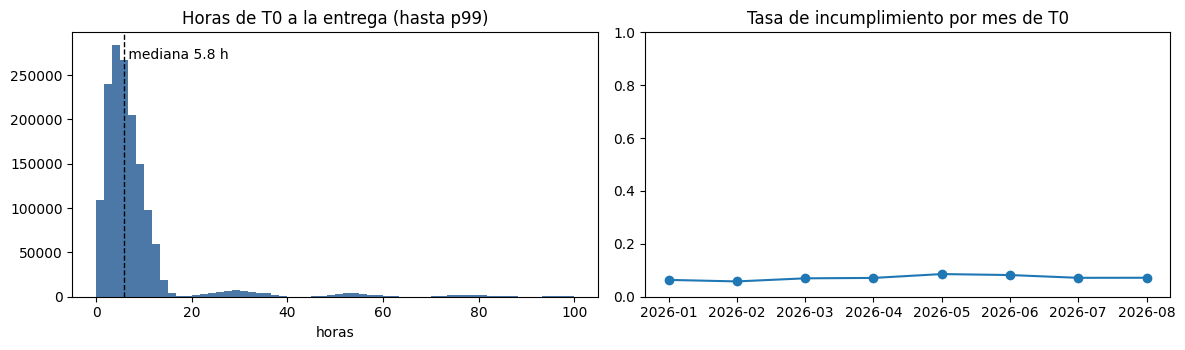

In [0]:
q = [0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 0.999]
cuant = pd.DataFrame({
    "h_ultima_milla (T0 a entrega)": d.h_ultima_milla.quantile(q),
    "h_admision_a_t0 (tránsito previo)": d.h_admision_a_t0.quantile(q),
    "h_total (admisión a entrega)": d.h_total.quantile(q),
    "sla_h": d.sla_h.quantile(q)}).round(2)
cuant.index = [f"q{x:g}" for x in q]
display(cuant); guardar(cuant, "02_cuantiles_tiempos")
estado = d.groupby("estado_desenlace").agg(guias=("estado_desenlace", "size"), prevalencia=("incumplimiento_sla", "mean"))
display(estado); guardar(estado, "02b_estado_desenlace")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
x = d.h_ultima_milla.dropna(); x = x[x <= x.quantile(0.99)]
axs[0].hist(x, bins=60, color="#4C78A8"); axs[0].set_title("Horas de T0 a la entrega (hasta p99)"); axs[0].set_xlabel("horas")
axs[0].axvline(x.median(), color="k", ls="--", lw=1); axs[0].text(x.median(), axs[0].get_ylim()[1]*.9, f" mediana {x.median():.1f} h")
m = d.groupby("mes_t0").agg(n=("incumplimiento_sla", "count"), k=("incumplimiento_sla", "sum"), med=("h_ultima_milla", "median"))
lo, hi = wilson(m.k, m.n)
axs[1].errorbar(m.index, m.k / m.n, yerr=[m.k / m.n - lo, hi - m.k / m.n], marker="o", capsize=3)
axs[1].set_title("Tasa de incumplimiento por mes de T0"); axs[1].set_ylim(0, 1)
plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}03_distribucion_y_mes.png", dpi=130); plt.show()

## 4. Perfiles por factor

Factores **temporales**, **espaciales**, **de operación** y **de servicio** conocidos en T0. Cada tabla trae guías, tasa con IC 95 %, mediana y percentil 90 de la última milla.

temporal · mes de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
171908,171908,10937,170353,6.2919,12.2042,0.0636,0.0625,0.0648,0.1106
206225,206225,11942,204431,5.95,11.8078,0.0579,0.0569,0.0589,0.1327
209806,209806,14598,208057,5.6146,12.242,0.0696,0.0685,0.0707,0.135
193214,193214,13735,191924,5.6566,12.7207,0.0711,0.0699,0.0722,0.1243
204833,204833,17553,202331,5.8675,13.4497,0.0857,0.0845,0.0869,0.1318
185344,185344,15198,183841,5.7618,13.3414,0.082,0.0808,0.0833,0.1193
246075,246075,17594,244689,5.7645,12.5104,0.0715,0.0705,0.0725,0.1584
136575,136575,9799,135690,5.6108,12.0033,0.0717,0.0704,0.0731,0.0879


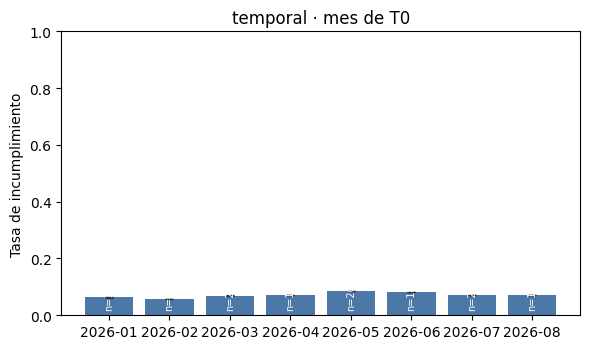

temporal · día de la semana


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
126574,126574,7794,125305,6.0249,12.8145,0.0616,0.0603,0.0629,0.0815
299457,299457,18586,296862,5.9463,12.2423,0.0621,0.0612,0.0629,0.1927
328609,328609,21411,325679,5.9557,12.1532,0.0652,0.0643,0.066,0.2115
299320,299320,19335,296905,5.9234,11.9566,0.0646,0.0637,0.0655,0.1926
276559,276559,17412,274368,5.8891,12.2072,0.063,0.0621,0.0639,0.178
222148,222148,26809,220884,5.0189,46.0851,0.1207,0.1193,0.122,0.143
1313,1313,9,1313,4.502,8.3478,0.0069,0.0036,0.013,8.0E-4


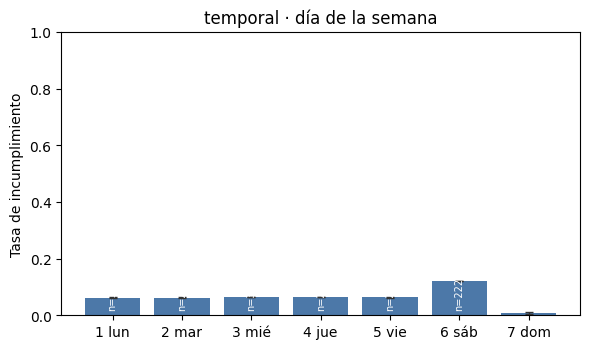

temporal · franja de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
50498,50498,7159,50242,9.8244,32.476,0.1418,0.1388,0.1448,0.0325
1487546,1487546,100014,1475526,5.6981,12.1041,0.0672,0.0668,0.0676,0.9572
1116,1116,437,1098,13.3603,17.6524,0.3916,0.3634,0.4205,7.0E-4
14820,14820,3746,14450,6.654,43.468,0.2528,0.2458,0.2598,0.0095


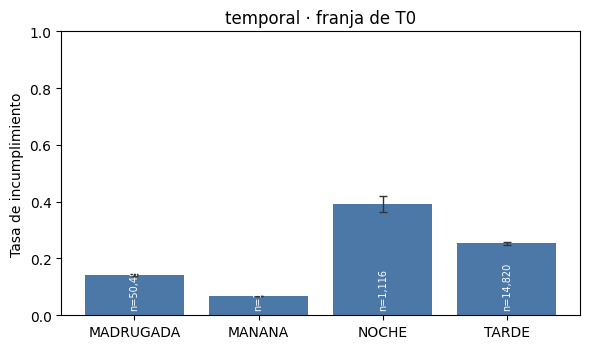

temporal · hora de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
94,94,3,91,16.6961,16.8498,0.0319,0.0109,0.0897,1.0E-4
467,467,47,463,11.2726,20.2691,0.1006,0.0765,0.1313,3.0E-4
4605,4605,474,4588,10.7901,26.9829,0.1029,0.0945,0.112,0.003
21989,21989,2879,21903,9.8684,32.0374,0.1309,0.1265,0.1355,0.0142
23342,23342,3756,23196,9.4501,33.8442,0.1609,0.1563,0.1657,0.015
49051,49051,4608,48466,7.0254,14.3501,0.0939,0.0914,0.0966,0.0316
173052,173052,9283,171963,6.3779,12.1298,0.0536,0.0526,0.0547,0.1114
337986,337986,21806,336031,5.8274,12.6169,0.0645,0.0637,0.0654,0.2175
502212,502212,29143,498396,5.289,11.5678,0.058,0.0574,0.0587,0.3232
368159,368159,26678,364431,5.5645,11.7146,0.0725,0.0716,0.0733,0.2369


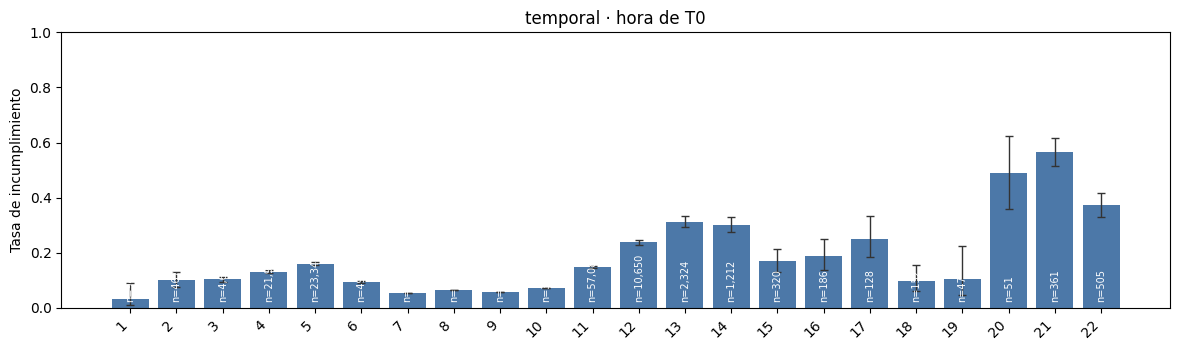

temporal · festivo


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
75,75,0,75,5.4042,8.0358,0.0,0.0,0.0487,0.0
1553905,1553905,111356,1541241,5.8106,12.4972,0.0717,0.0713,0.0721,1.0


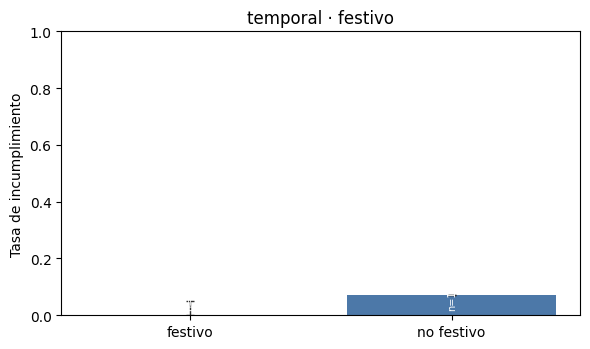

espacial · categoría de zona


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
928374,928374,52992,919615,5.4319,11.458,0.0571,0.0566,0.0576,0.5974
4987,4987,546,4978,3.8387,18.4031,0.1095,0.1011,0.1185,0.0032
167389,167389,8269,165637,5.7567,11.662,0.0494,0.0484,0.0504,0.1077
8066,8066,6111,7074,52.5954,194.3449,0.7576,0.7482,0.7669,0.0052
302186,302186,18131,301329,5.9097,11.7508,0.06,0.0592,0.0609,0.1945
142953,142953,25298,142660,8.4262,51.4919,0.177,0.175,0.179,0.092


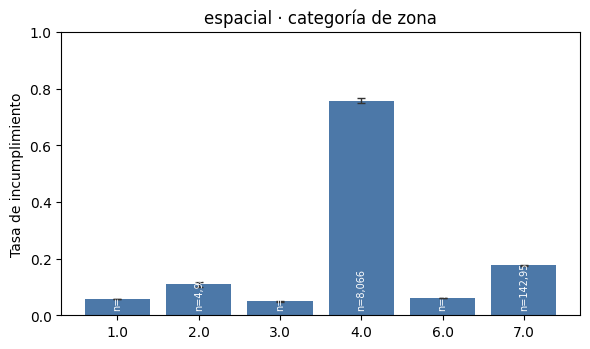

espacial · regional de origen


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
135414,135414,10949,133948,5.4041,12.2879,0.0809,0.0794,0.0823,0.0871
511834,511834,38094,509011,6.1624,12.8267,0.0744,0.0737,0.0751,0.3294
39722,39722,3292,39367,5.6912,12.7415,0.0829,0.0802,0.0856,0.0256
127923,127923,8956,126591,5.4681,11.9954,0.07,0.0686,0.0714,0.0823
37876,37876,3028,37566,5.474,12.6558,0.0799,0.0773,0.0827,0.0244
182487,182487,12585,179250,5.4843,12.3019,0.069,0.0678,0.0701,0.1174
96736,96736,7609,95487,5.3084,12.1712,0.0787,0.077,0.0804,0.0623
84115,84115,6831,83468,5.5637,12.8195,0.0812,0.0794,0.0831,0.0541
299334,299334,17303,298449,6.095,12.2989,0.0578,0.057,0.0586,0.1926
38539,38539,2709,38179,5.4287,12.0563,0.0703,0.0678,0.0729,0.0248


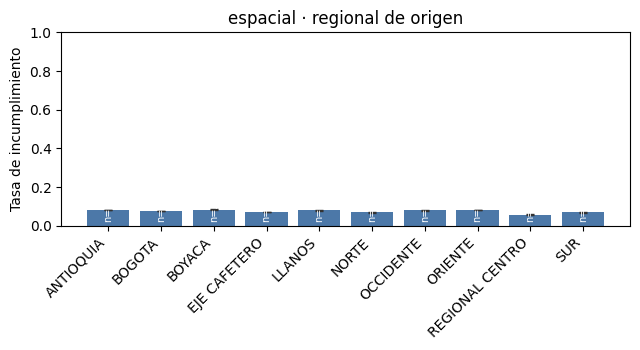

operación · piezas declaradas


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
1516982,1516982,109272,1504650,5.8375,12.5375,0.072,0.0716,0.0724,0.9762
14205,14205,866,14061,5.1597,10.7888,0.061,0.0571,0.065,0.0091
10510,10510,453,10434,4.9093,9.767,0.0431,0.0394,0.0472,0.0068
7034,7034,317,6992,4.0566,8.5076,0.0451,0.0405,0.0502,0.0045
5249,5249,448,5179,5.3528,12.9013,0.0853,0.0781,0.0932,0.0034


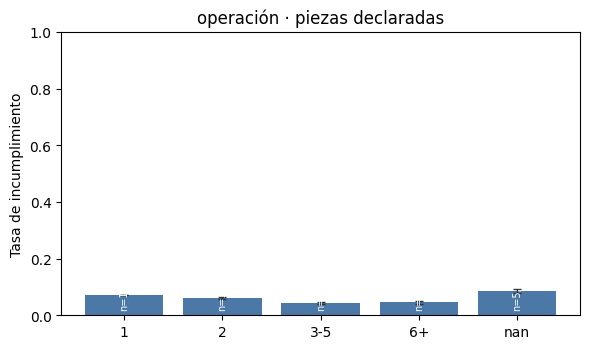

operación · decil de peso


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
44672,44672,2592,44634,6.1567,12.4052,0.058,0.0559,0.0602,0.0287
102970,102970,5813,102926,5.479,11.5448,0.0565,0.0551,0.0579,0.0663
84972,84972,5089,84929,6.1718,12.6025,0.0599,0.0583,0.0615,0.0547
85835,85835,5136,85765,6.2404,12.5189,0.0598,0.0583,0.0614,0.0552
59869,59869,3075,59845,6.0789,12.2679,0.0514,0.0496,0.0532,0.0385
100150,100150,5406,100130,6.1645,12.3044,0.054,0.0526,0.0554,0.0644
109038,109038,6493,109009,6.2115,12.3463,0.0595,0.0582,0.061,0.0702
112743,112743,6674,112704,6.2254,12.4116,0.0592,0.0578,0.0606,0.0726
113905,113905,6719,113875,6.2558,12.4494,0.059,0.0576,0.0604,0.0733
93572,93572,5465,93540,5.9054,12.2089,0.0584,0.0569,0.0599,0.0602


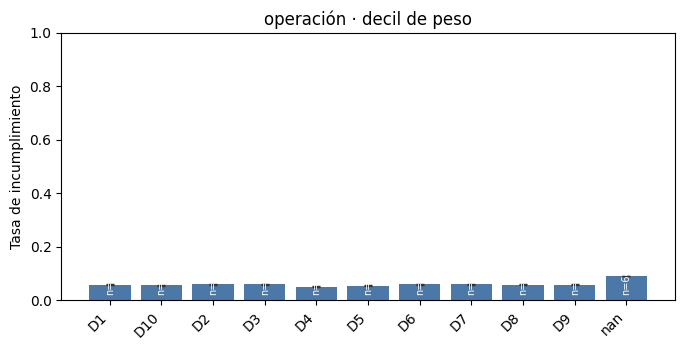

operación · re-despachos


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
1485300,1485300,51813,1475835,5.6249,11.2593,0.0349,0.0346,0.0352,0.9558
60084,60084,51119,58406,51.5505,103.9981,0.8508,0.8479,0.8536,0.0387
6480,6480,6352,5651,104.1419,217.2907,0.9802,0.9766,0.9834,0.0042
1475,1475,1452,1068,156.5156,505.9584,0.9844,0.9767,0.9896,9.0E-4
413,413,399,236,247.3243,755.1272,0.9661,0.9439,0.9797,3.0E-4
140,140,136,80,299.5665,845.5883,0.9714,0.9288,0.9888,1.0E-4
58,58,56,28,401.4241,1169.3729,0.9655,0.8827,0.9905,0.0


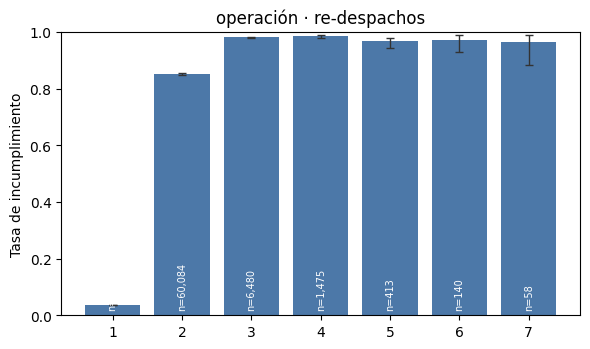

servicio · producto


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
468686,468686,34799,462424,5.2914,12.3305,0.0742,0.0735,0.075,0.3016
830559,830559,63015,825017,6.1229,12.7904,0.0759,0.0753,0.0764,0.5345
176082,176082,7600,176017,5.7273,11.6785,0.0432,0.0422,0.0441,0.1133
25616,25616,1852,25262,4.4993,11.6107,0.0723,0.0692,0.0755,0.0165
5435,5435,187,5427,4.2432,9.8217,0.0344,0.0299,0.0396,0.0035
83,83,2,83,2.9184,7.8703,0.0241,0.0066,0.0837,1.0E-4
39,39,1,39,6.2264,10.8764,0.0256,0.0045,0.1318,0.0
3895,3895,535,3849,7.1035,34.9897,0.1374,0.1269,0.1485,0.0025
72,72,11,67,7.8966,89.0663,0.1528,0.0875,0.2532,0.0
3013,3013,238,2976,5.9826,12.3871,0.079,0.0699,0.0892,0.0019


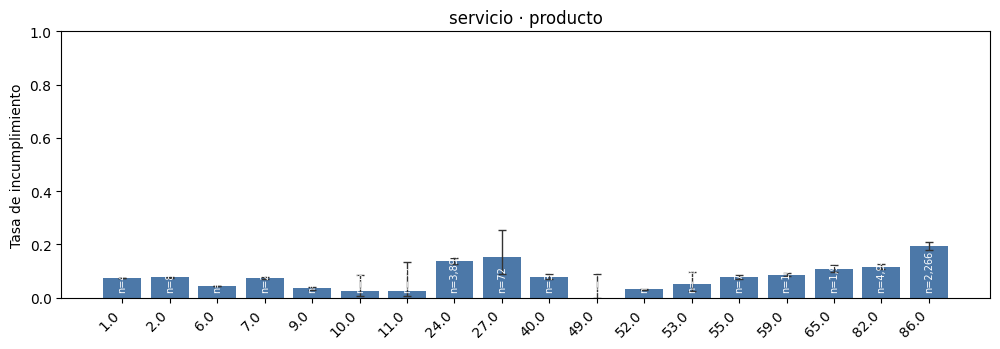

servicio · tipo de guía


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
10744,10744,252,10724,4.5795,9.8886,0.0235,0.0208,0.0265,0.0069
14583,14583,1134,14583,5.1717,12.4024,0.0778,0.0735,0.0822,0.0094
352,352,27,352,6.0071,13.7372,0.0767,0.0532,0.1093,2.0E-4
10856,10856,705,10822,6.2246,12.2009,0.0649,0.0605,0.0697,0.007
85864,85864,4297,85848,6.4174,12.3675,0.05,0.0486,0.0515,0.0553
82493,82493,5726,82460,6.0934,12.6474,0.0694,0.0677,0.0712,0.0531
124,124,7,124,5.2997,13.8786,0.0565,0.0276,0.1119,1.0E-4
10736,10736,761,10729,5.8141,12.5107,0.0709,0.0662,0.0759,0.0069
6775,6775,30,6775,3.6386,9.6743,0.0044,0.0031,0.0063,0.0044
1408,1408,146,1358,5.6654,13.0482,0.1037,0.0888,0.1207,9.0E-4


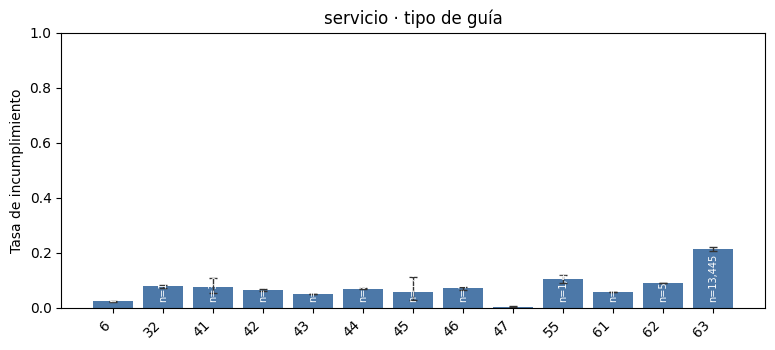

servicio · SLA comprometido (h)


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
3479,3479,310,3469,3.8588,9.2898,0.0891,0.0801,0.099,0.0022
1291482,1291482,93863,1282489,5.8536,12.4811,0.0727,0.0722,0.0731,0.8311
221240,221240,15496,218081,5.5908,12.5618,0.07,0.069,0.0711,0.1424
20394,20394,1059,20178,5.6264,12.5837,0.0519,0.049,0.0551,0.0131
8802,8802,396,8658,5.8279,13.2107,0.045,0.0409,0.0495,0.0057
5050,5050,191,4952,5.9218,12.8767,0.0378,0.0329,0.0434,0.0032
1516,1516,22,1503,6.0291,12.7426,0.0145,0.0096,0.0219,0.001
677,677,8,662,6.5758,14.4535,0.0118,0.006,0.0231,4.0E-4
1318,1318,9,1302,5.7271,12.0763,0.0068,0.0036,0.0129,8.0E-4


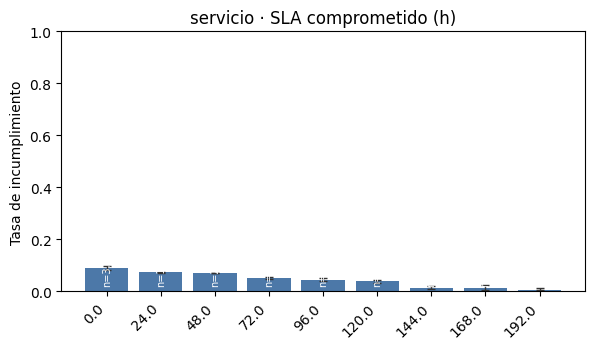

servicio · margen de SLA en T0 (h)


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
467,467,401,452,13.2498,16.0562,0.8587,0.8241,0.8873,3.0E-4
1352651,1352651,102503,1341860,5.8089,12.4978,0.0758,0.0753,0.0762,0.8704
136082,136082,3893,134837,5.8754,11.751,0.0286,0.0277,0.0295,0.0876
12094,12094,3541,11774,7.5135,47.2433,0.2928,0.2847,0.301,0.0078
52686,52686,1018,52393,5.4817,13.2504,0.0193,0.0182,0.0205,0.0339


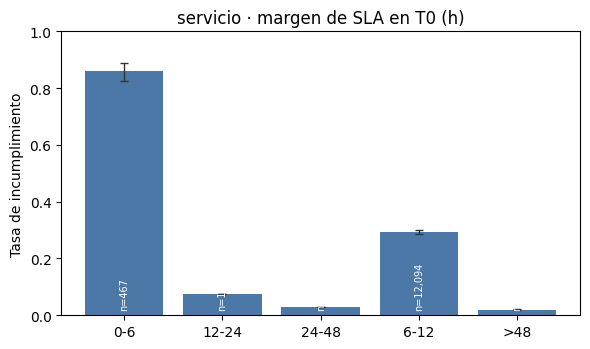

In [0]:
FACTORES = {
    "temporal · mes de T0": "mes_t0", "temporal · día de la semana": "dia_semana", "temporal · franja de T0": "franja",
    "temporal · hora de T0": "hora_t0", "temporal · festivo": "festivo_t0",
    "espacial · categoría de zona": "categoria_zona", "espacial · regional de origen": "regional_origen",
    "operación · piezas declaradas": "piezas_cat", "operación · decil de peso": "peso_decil",
    "operación · re-despachos": "n_salidas_zona",
    "servicio · producto": "ID_PRODUCTO", "servicio · tipo de guía": "ID_TIPOGUIA",
    "servicio · SLA comprometido (h)": "sla_h", "servicio · margen de SLA en T0 (h)": "margen_cat"}
perfiles = {}
for i, (titulo, col) in enumerate(FACTORES.items(), start=1):
    t = perfil(d, col); perfiles[col] = t
    print(titulo); display(t)
    guardar(t, f"04_{i:02d}_{col}")
    if 1 < len(t) <= 25:
        grafico_tasa(t, titulo, f"04_{i:02d}_{col}", rot=45 if len(t) > 8 else 0)

In [0]:
# Zonas urbanas: las 15 de mayor y menor tasa (con n >= N_MIN)
z = perfil(d, "zona_urbana", orden="tasa_incumplimiento")
display(pd.concat([z.head(15), z.tail(15)])); guardar(z, "04_zonas_urbanas")
print(f"{len(z)} zonas con al menos {N_MIN} guías; rango de tasas {z.tasa_incumplimiento.min():.2f}–{z.tasa_incumplimiento.max():.2f}")

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
45,45,45,45,31.3973,37.8988,1.0,0.9213,1.0,0.0
39,39,39,39,78.6389,137.5223,1.0,0.9103,1.0,0.0
40,40,39,38,67.4674,139.9112,0.975,0.8712,0.9956,0.0
71,71,69,70,126.7609,316.5263,0.9718,0.903,0.9922,0.0
31,31,30,31,52.0953,242.6886,0.9677,0.8381,0.9943,0.0
1313,1313,1256,1235,54.8203,148.9716,0.9566,0.9442,0.9663,8.0E-4
85,85,81,81,142.7687,289.7732,0.9529,0.8852,0.9816,1.0E-4
41,41,39,39,74.2846,170.2083,0.9512,0.8386,0.9865,0.0
40,40,38,39,99.2826,268.1583,0.95,0.835,0.9862,0.0
33,33,31,31,80.7147,177.2255,0.9394,0.8039,0.9832,0.0


550 zonas con al menos 30 guías; rango de tasas 0.00–1.00


## 5. Interacción zona × franja (mediana de horas de última milla)

MADRUGADA,MANANA,NOCHE,TARDE
12.0,5.4,0.3,5.0
null,3.8,null,null
8.6,5.8,0.0,2.6
35.0,53.4,41.4,50.7
null,null,null,null
8.6,5.9,null,9.6
9.7,7.6,13.6,25.7
null,null,null,null


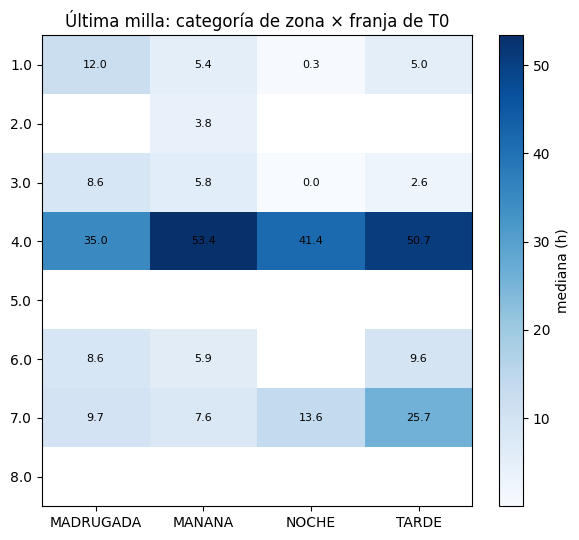

In [0]:
tab = d.pivot_table(index="categoria_zona", columns="franja", values="h_ultima_milla", aggfunc="median", observed=True)
cnt = d.pivot_table(index="categoria_zona", columns="franja", values="h_ultima_milla", aggfunc="count", observed=True)
tab = tab.where(cnt >= N_MIN)
display(tab.round(1)); guardar(tab.round(2), "05_zona_x_franja_mediana")
fig, ax = plt.subplots(figsize=(6, 0.5 * len(tab) + 1.5))
im = ax.imshow(tab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns); ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        if pd.notna(tab.values[i, j]): ax.text(j, i, f"{tab.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="mediana (h)"); ax.set_title("Última milla: categoría de zona × franja de T0")
plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}05_zona_x_franja.png", dpi=130); plt.show()

## 6. Clima previo a T0 (solo si existe la base de 0160)

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
2700,2700,124,2677,6.0435,10.153,0.0459,0.0387,0.0545,0.0017
459047,459047,31977,455638,5.8057,12.3059,0.0697,0.0689,0.0704,0.2954
757279,757279,56691,750895,5.7604,12.6739,0.0749,0.0743,0.0755,0.4873
318286,318286,21552,315616,5.8924,12.4393,0.0677,0.0668,0.0686,0.2048
16668,16668,1012,16490,6.4199,12.1884,0.0607,0.0572,0.0644,0.0107


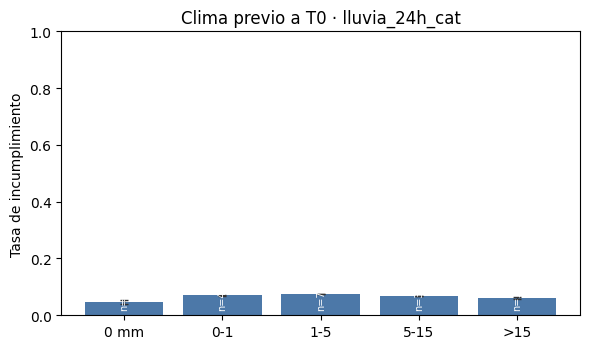

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
705813,705813,45876,700736,5.8982,12.4086,0.065,0.0644,0.0656,0.4542
15496,15496,1071,15344,5.3623,12.2358,0.0691,0.0652,0.0732,0.01
831362,831362,64244,823947,5.7421,12.5881,0.0773,0.0767,0.0779,0.535
1309,1309,165,1289,5.2959,20.3824,0.1261,0.1092,0.1451,8.0E-4


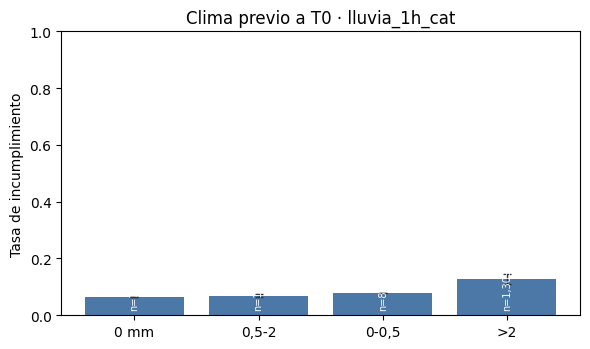

Guías con clima completo: 1,553,980 de 1,553,980. Lectura descriptiva: el clima es reanálisis retrospectivo.


In [0]:
if usa_clima:
    dc = d[d.CLIMA_COMPLETO.fillna(False).astype(bool)].copy()
    dc["lluvia_24h_cat"] = pd.cut(dc.LLUVIA_24H_PREV, [-0.01, 0.0, 1, 5, 15, np.inf],
                                  labels=["0 mm", "0-1", "1-5", "5-15", ">15"]).astype(str)
    dc["lluvia_1h_cat"] = pd.cut(dc.PRECIP_PREV_1H, [-0.01, 0.0, 0.5, 2, np.inf], labels=["0 mm", "0-0,5", "0,5-2", ">2"]).astype(str)
    for col in ["lluvia_24h_cat", "lluvia_1h_cat"]:
        t = perfil(dc, col); display(t); guardar(t, f"06_{col}")
        grafico_tasa(t, f"Clima previo a T0 · {col}", f"06_{col}")
    print(f"Guías con clima completo: {len(dc):,} de {len(d):,}. Lectura descriptiva: el clima es reanálisis retrospectivo.")
else:
    print("No existe la base con clima de 0160: sección omitida.")

## 7. Ordenamiento de factores por su relación con el retraso

Medidas univariadas y descriptivas, comparables entre factores:
- **Incumplimiento:** AUC de la tasa del grupo usada como puntaje (0,5 = sin relación). Los grupos con menos de `N_MIN` se agrupan en «OTROS».
- **Última milla:** razón de correlación η² (proporción de la varianza de las horas explicada por el grupo).

Para las variables continuas se usan sus categorías. No es una medida de importancia en un modelo multivariado (eso es 0420).

In [0]:
from sklearn.metrics import roc_auc_score
def eta2(y, g):
    m = y.groupby(g, observed=True).transform("mean")
    return float(((m - y.mean())**2).sum() / ((y - y.mean())**2).sum())
filas = []
candidatas = list(FACTORES.values()) + ["zona_urbana"] + (["lluvia_24h_cat"] if usa_clima else [])
base = dc if usa_clima else d
for col in candidatas:
    src = base if col.startswith("lluvia") else d
    g = src[col].astype(str)
    frec = g.map(g.value_counts()); g = g.where(frec >= N_MIN, "OTROS")
    e = src.incumplimiento_sla.notna()
    tasa = src.loc[e, "incumplimiento_sla"].groupby(g[e]).transform("mean")
    auc = roc_auc_score(src.loc[e, "incumplimiento_sla"], tasa) if src.loc[e, "incumplimiento_sla"].nunique() == 2 else np.nan
    r = src.h_ultima_milla.notna()
    filas.append({"factor": col, "categorias": g.nunique(), "AUC_incumplimiento": auc,
                  "eta2_ultima_milla": eta2(src.loc[r, "h_ultima_milla"], g[r]), "guias": len(src)})
rank = pd.DataFrame(filas).set_index("factor").sort_values("AUC_incumplimiento", ascending=False).round(4)
display(rank); guardar(rank, "07_ranking_factores")

categorias,AUC_incumplimiento,eta2_ultima_milla,guias
551,0.7749,0.0479,1553980
8,0.7644,0.1807,1553980
7,0.6108,0.0272,1553980
23,0.5823,0.0036,1553980
14,0.5746,0.001,1553980
11,0.5641,5.0E-4,1553980
7,0.5571,0.0013,1553980
5,0.5545,0.0013,1553980
8,0.5347,3.0E-4,1553980
19,0.5342,5.0E-4,1553980


## Cómo leer y qué entregar

- `01_exclusiones`: si un motivo tiene una tasa de incumplimiento muy distinta de la general, excluirlo cambia la población; debe decirse en 4.2.2.
- `02_cuantiles_tiempos`: cifra para el documento («la mediana de última milla es X h»), siempre con su `n`.
- `04_*` y `05_*`: tablas del OE1 con denominador e IC. No interpretar diferencias cuyos IC se solapan.
- `07_ranking_factores`: insumo para la discusión del OE1 y para comparar con la interpretabilidad del modelo (0420).

**Entregar:** la carpeta `V4/EDA/` completa (CSV y PNG). Ninguna salida contiene guías individuales.